# <center> Практические задания по цифровой обработке сигналов </center>
# <center> Вторая лабораторная работа </center>
# <center> Анализ сигналов </center>

In [1]:
import librosa
import numpy as np
import scipy 
import scipy.fft
import IPython.display as ipd
import matplotlib.pyplot as plt
import librosa.display
import librosa.filters
import hashlib

# Запретим numpy выполнять деление на 0
np.seterr(divide='raise', invalid='raise') 
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# ['retina', 'png', 'jpeg', 'svg', 'pdf']

In [2]:
# Определим две функции для отрисовки сигнала. 
def draw_waveform(wav, sr, figsize=(14, 5)):
    # Отрисовка звукового сигнала во временной области
    plt.figure(figsize=figsize)
    librosa.display.waveplot(wav, sr=sr)

def draw_sig(frames, name=None, figsize=(14, 3)):
    # Отрисовка сигнала в виде "леденцов на палочке"
    plt.figure(figsize=figsize)
    plt.stem(frames)
    if name is not None:
        plt.legend([name])
    plt.xlabel("n")
    plt.ylabel("Energy")
    plt.show()

In [3]:
# Создадим несколько простых сигналов. Они нам понадобятся для дальшейшего тестирования
signals = {}

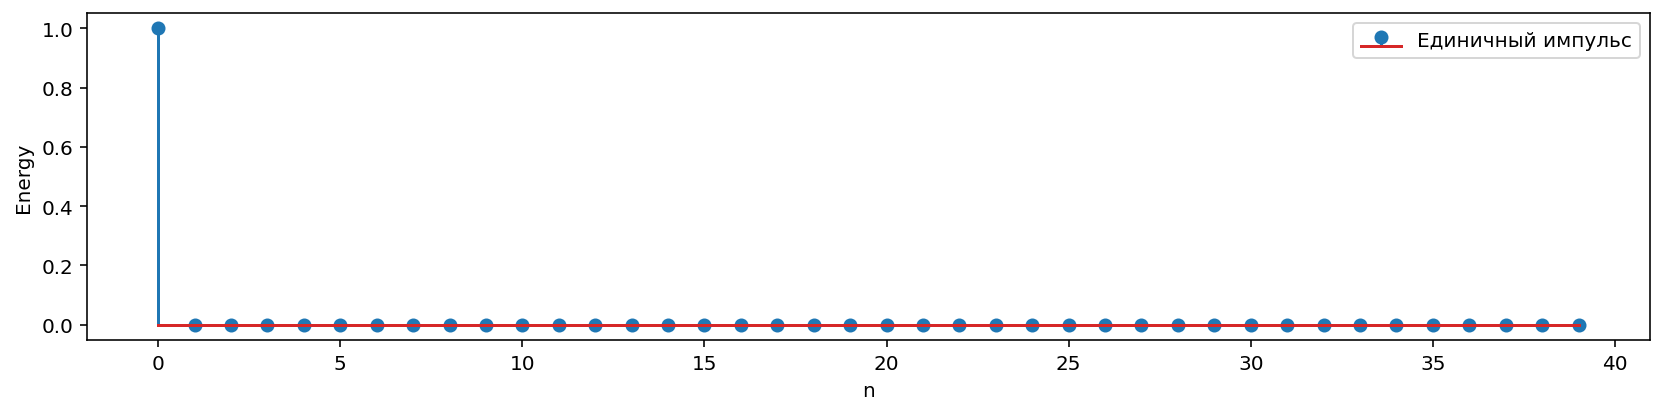

In [4]:
name = "Единичный импульс"
signals[name] = np.array([1] + [0]*39, dtype=float)
draw_sig(signals[name], name)

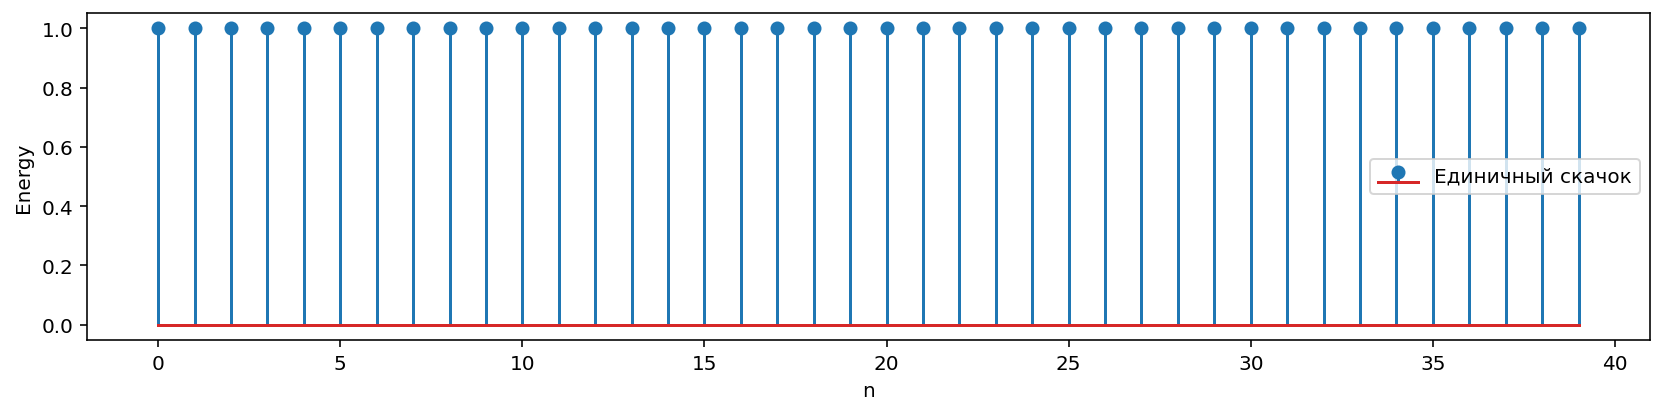

In [5]:
name = "Единичный скачок"
signals[name] = np.array([1]*40 ,dtype=float) 
draw_sig(signals[name], name)

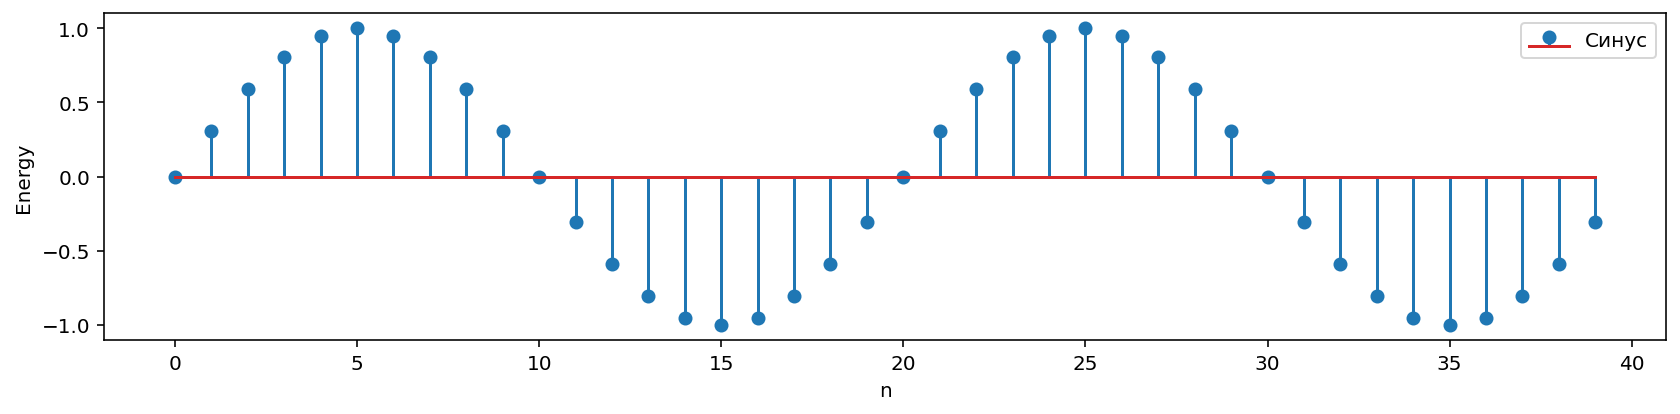

In [6]:
name = "Синус"
signals[name] = np.sin(np.pi * np.arange(40)/10)
draw_sig(signals[name], name)

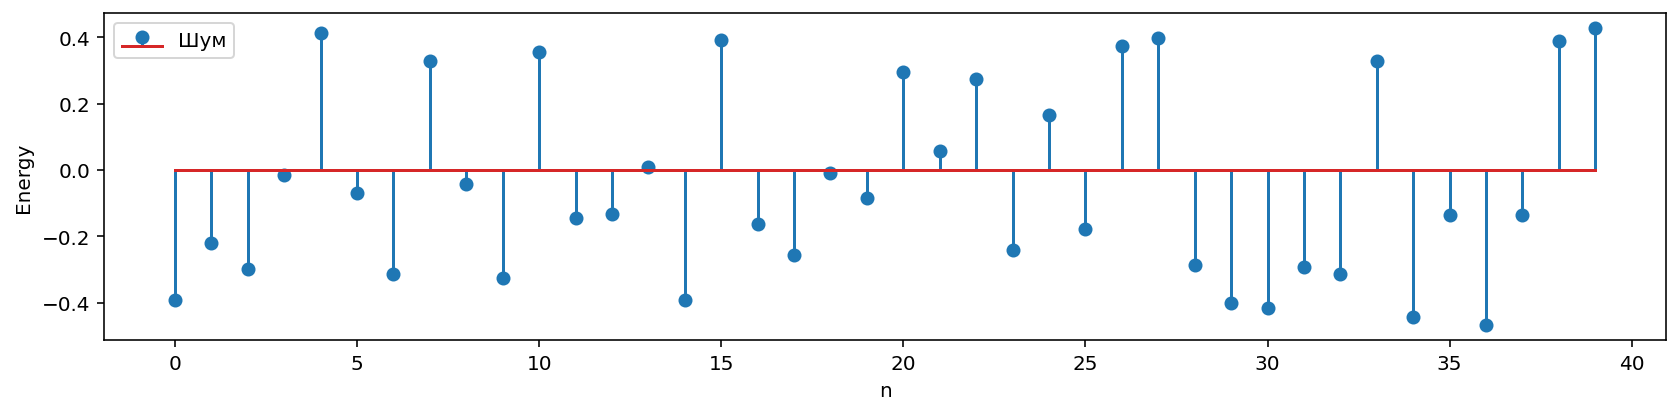

In [7]:
name = "Шум"
signals[name] = np.random.random(40)-0.5
draw_sig(signals[name], name)

-------------------------------
# Преобразование Фурье
Прежде, чем перейти к анализу сигналов, надо разобраться, что такое преобразование Фурье. 
> Преобразование Фурье (символ ℱ) — операция, сопоставляющая одной функции вещественной переменной другую функцию вещественной переменной. Эта новая функция описывает коэффициенты («амплитуды») при разложении исходной функции на элементарные составляющие — гармонические колебания с разными частотами (подобно тому, как музыкальный аккорд может быть выражен в виде суммы музыкальных звуков, которые его составляют). [Wiki](https://ru.wikipedia.org/wiki/%D0%9F%D1%80%D0%B5%D0%BE%D0%B1%D1%80%D0%B0%D0%B7%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5_%D0%A4%D1%83%D1%80%D1%8C%D0%B5)



Формула прямого дискретного преобразования Фурье (ДПФ, Discrete Fourier Transform, DFT):
$$ X_k = \sum_{n=0}^{N-1} x_{n} \cdot e^{-i \frac{2\pi}{N} k n} $$


# Задание 1 (2 балла)
Реализовать дискретное преобразование Фурье. Сравнить с реализацией scipy.fft.fft

In [8]:
def DFT(x):
    x = np.asarray(x, dtype=float)
    N = x.shape[0]
    n = np.arange(N)
    k = n.reshape((N, 1))
    M = np.exp(-2j * np.pi * k * n / N)
    return M @ x

#def DFT(x):
#    return np.array([sum((x[k] * np.exp(-2j * np.pi * k * n / len(x)) for k in range(len(x)))) for n in range(len(x))])

In [9]:
def test_DTF(x, transform=DFT):
    # Сравнение с библиотекой scipy
    scipy_result = scipy.fft.fft(x)
    curr_result = transform(x)
    if scipy_result.shape != curr_result.shape:
        print("TEST_FAILED")
        print(f"Your spectrogram shape is {curr_result.shape}. "
              f"Scipy spectrogram shape is {scipy_result.shape}")
        return -1
    if not np.allclose(curr_result, scipy_result):
        print("TEST FAILED")
        print(f"scipy spectrogram: {scipy_result}")
        print(f"Your DTF spectrogram: {curr_result}")
        print(f"Average diff is {np.mean(np.abs(scipy_result - curr_result))}")
        return -2
    print("TEST PASSED")
    return 0

for name, sig in signals.items():
    print(f"Checking '{name}'")
    assert test_DTF(sig) == 0, "Check you implementation"
print("All ok!")

Checking 'Единичный импульс'
TEST PASSED
Checking 'Единичный скачок'
TEST PASSED
Checking 'Синус'
TEST PASSED
Checking 'Шум'
TEST PASSED
All ok!


Класическое ДПФ имеет существенный недостаток - сложность алгоритма $O(N^2)$. На данный момент существуют чуть более сложные реализации преобразования Фурье, которые избавляются от квадратичной сложности. Например, алгоритм быстрого преобразования Фурье (Fast Fourier Transform, FFT) имеет сложность $O(N log(N))$, что делает его значительно более быстрым на длинных последовательностях. 

# Задание 1.1* (1 балл)
Реализовать быстрое преобразование Фурье. Сравнить с scipy.fft.fft

In [10]:
def FFT(x):
    x = np.asarray(x, dtype=float)
    N = x.shape[0]
    if N <= 8: # cutoff 
        return DFT(x)
    else:
        X_even, X_odd = FFT(x[::2]), FFT(x[1::2]) # recursive
        freqs = np.exp(-2j * np.pi * np.arange(N) / N)
        return np.hstack([X_even + freqs[:N // 2] * X_odd, X_even + freqs[N // 2:] * X_odd])

In [11]:
for name, sig in signals.items():
    print(f"Checking '{name}'")
    assert test_DTF(sig, transform=FFT) == 0, "Check you implementation"
print("All ok!")

Checking 'Единичный импульс'
TEST PASSED
Checking 'Единичный скачок'
TEST PASSED
Checking 'Синус'
TEST PASSED
Checking 'Шум'
TEST PASSED
All ok!


# Амплитудный и фазовый спектры
Поскольку преобразование Фурье определено в комплекстной области, анализировать результат напрямую проблематично. Для анализа сигналов принято разбивать результат преобразования Фурье на два спектра: амплитудный и фазовый. Амплитудный показывает, как меняется модуль сигнала, а фазовый - как меняется угол, образуемый на комплексной плоскости. 
# Задание 2 (1 балл)

Реализовать функции построения амплитудного и фазового спектра

In [12]:
#функция построения амплитудного спектра
def get_magnitude_from_spec(spec):
    return np.abs(spec)

#функция построения фазового спектра
def get_phi_from_spec(spec):
    return np.angle(spec)

In [13]:
def check_mean_var(sig, mean=None, var=None):
    if mean is not None and np.mean(sig) != mean:
        print(f"Bad mean. Expected {mean}, got {np.mean(sig)}")
        return False
    if var is not None and np.var(sig) != var:
        print(f"Bad var. Expected {var}, got {np.var(sig)}")
        return False
    return True

_spec = scipy.fft.fft(np.array([1]+[0]*10))
assert check_mean_var(get_magnitude_from_spec(_spec), 1.0, 0.0), \
    "Wrong magnitude"
assert check_mean_var(get_phi_from_spec(_spec), 0.0, 0.0), \
    "Wrong phase"

    
_spec = scipy.fft.fft(np.array([1]*10))
assert check_mean_var(get_magnitude_from_spec(_spec), 1.0, 9.0), \
    "Wrong  magnitude"
assert get_magnitude_from_spec(_spec)[0] == 10, \
    "Wrong magnitude"
assert get_phi_from_spec(_spec)[0] == 0, \
    "Wrong phase"

_spec = scipy.fft.fft(scipy.fft.ifft(np.array([0] + [10+5j]+[0]*6 + [10-5j])))
assert get_magnitude_from_spec(_spec).round(1)[1] == 11.2 , \
    "Wrong magnitude. Make sure it is a complex number module."
assert get_phi_from_spec(_spec).round(1)[1] == 0.5 , \
    "Wrong phase. Make sure it is an angle."

   
print("All OK!")

All OK!


In [15]:
# Определим еще одну функцию для отрисовки
# Теперь будем рисовать сигнал в частотной области
def draw_spec(spec, name=None, draw_A=True, draw_p=True, figsize=(14, 3)):
    if len(spec)<100:
        # Рисуем точки как "леденцы на палочках"
        draw_func = plt.stem
    else:
        # При большом N "леденцы" выглядят плохо, 
        # Поэтому будем рисовать огибающую функцию
        draw_func = plt.plot
    
    if draw_A:
        plt.figure(figsize=figsize)
        plt.title("Magnitude spectrum")
        spec_A = get_magnitude_from_spec(spec)
        draw_func(spec_A)
        plt.ylabel("Magnitude")
        plt.xlabel("n")
        if name is not None:
            plt.legend([name])
        plt.show()
        
    if draw_p:
        plt.figure(figsize=figsize)
        plt.title("Phase spectrum")
        phi = get_phi_from_spec(spec)
        draw_func(phi)
        plt.ylabel("Radian")
        plt.xlabel("n")
        if name is not None:
            plt.legend([name])
        plt.show()
    return 

# Задание 2.1 (0.5 балла)

Постройте спектры для всех сигналов из коллекции signals и ответьте на вопросы:

1. Почему амплитуда всех гармоник единичного импульса равна единице? 
2. Какие выводы можно сделать смотря на амплитудный спектр? А на фазовый? 
3. Как перевести номер отсчета в частоту?  
4. Что в фазовом спектре является полезной информацией, а что - шумом? Почему?

Единичный импульс:


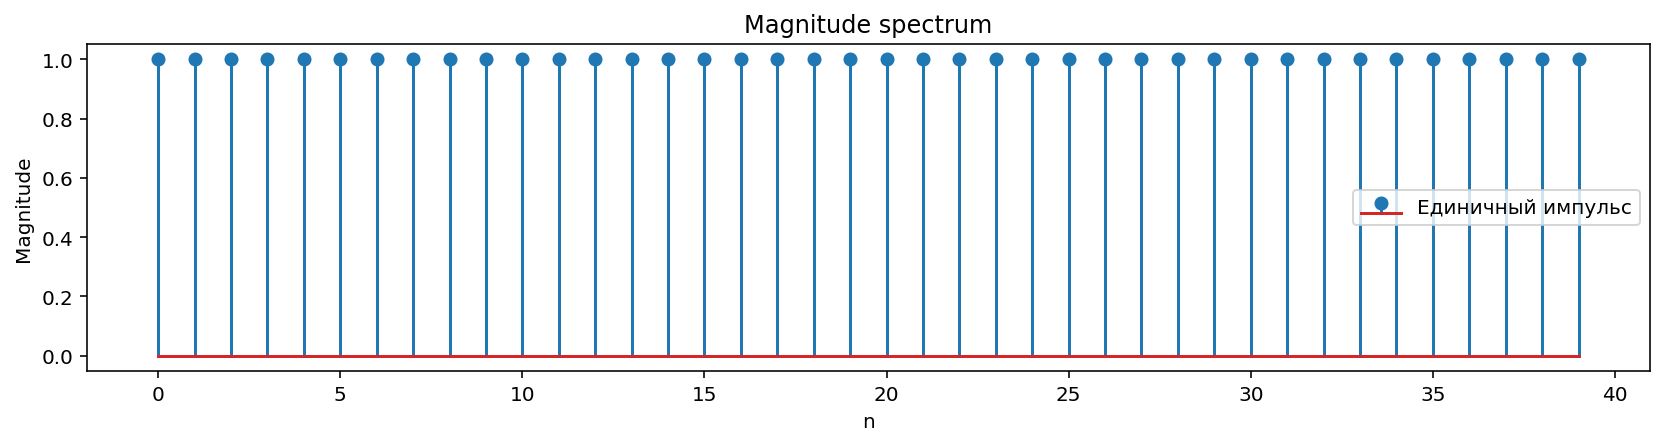

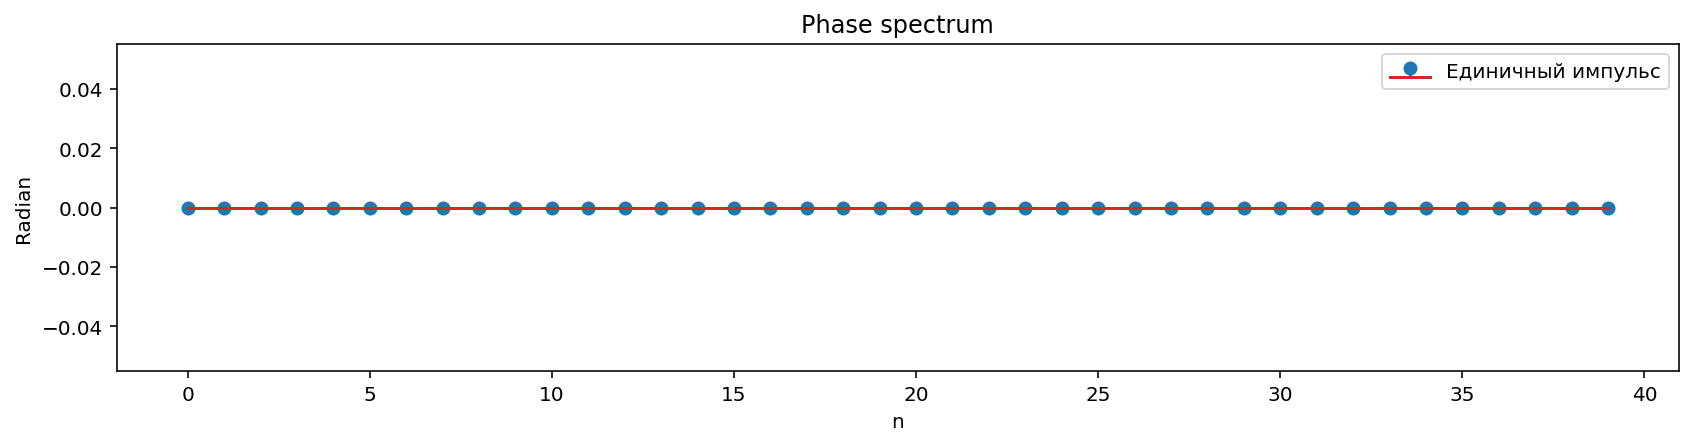

Единичный скачок:


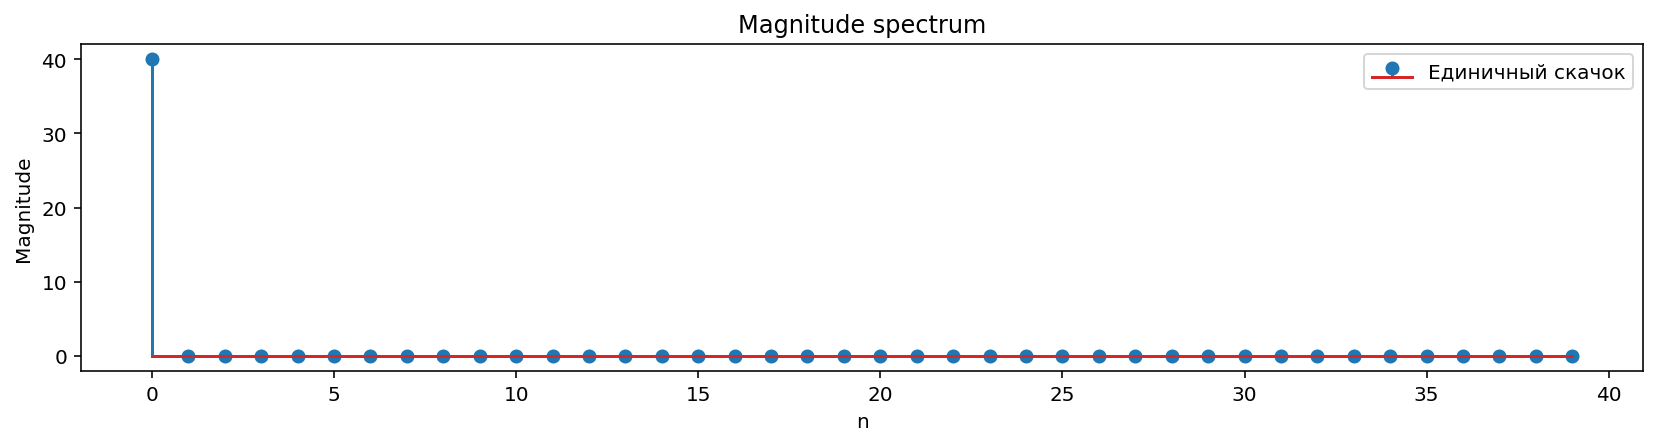

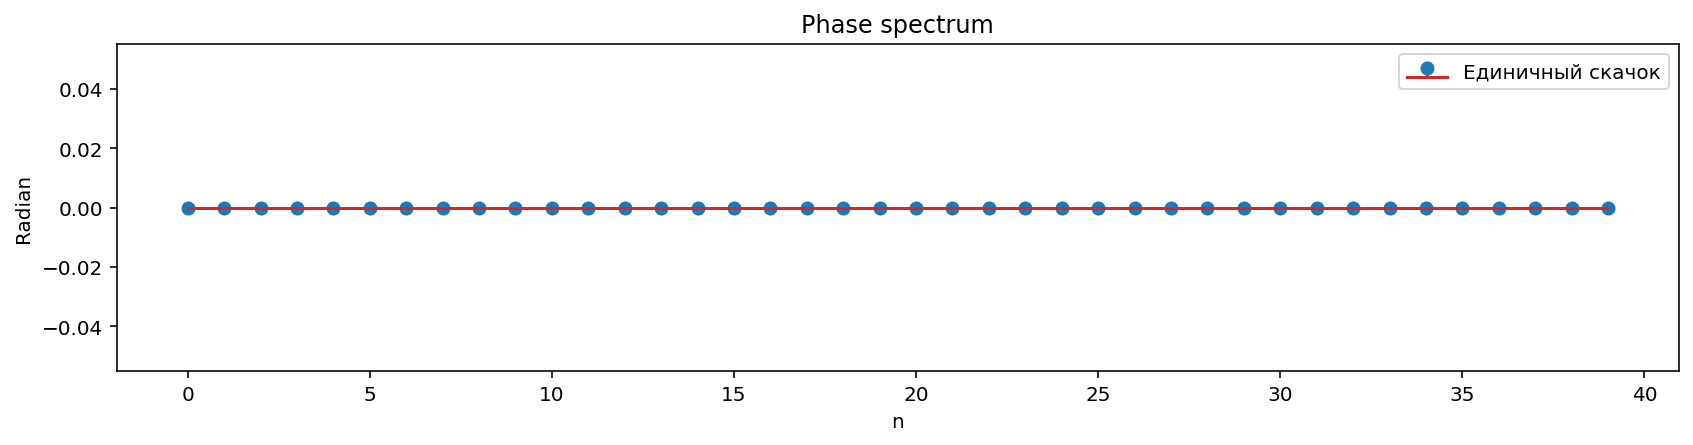

Синус:


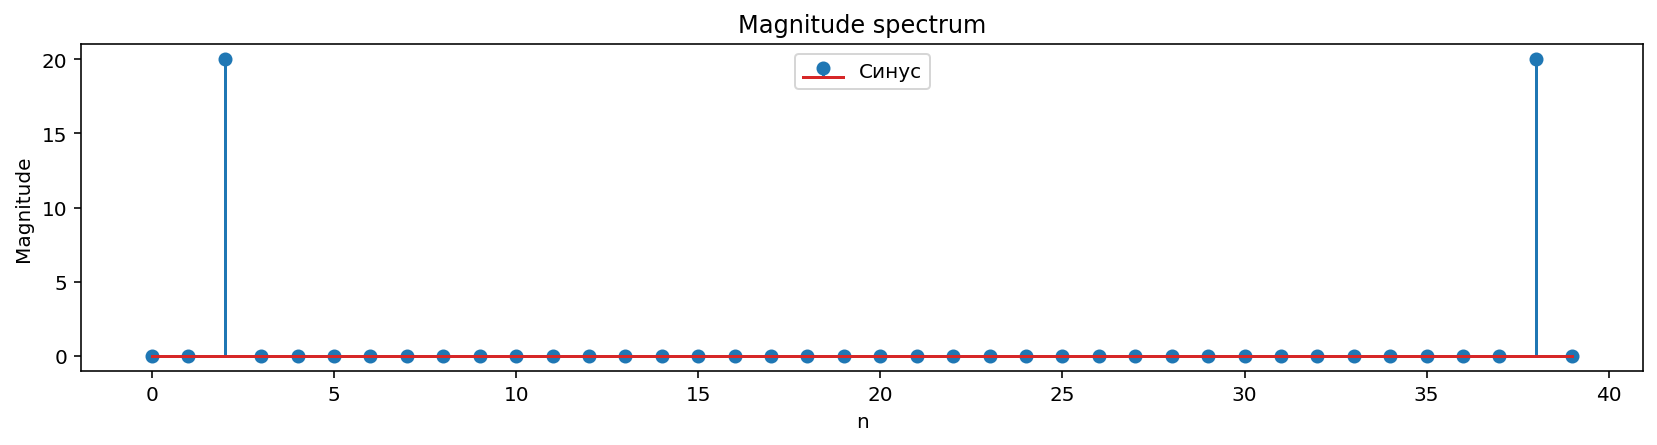

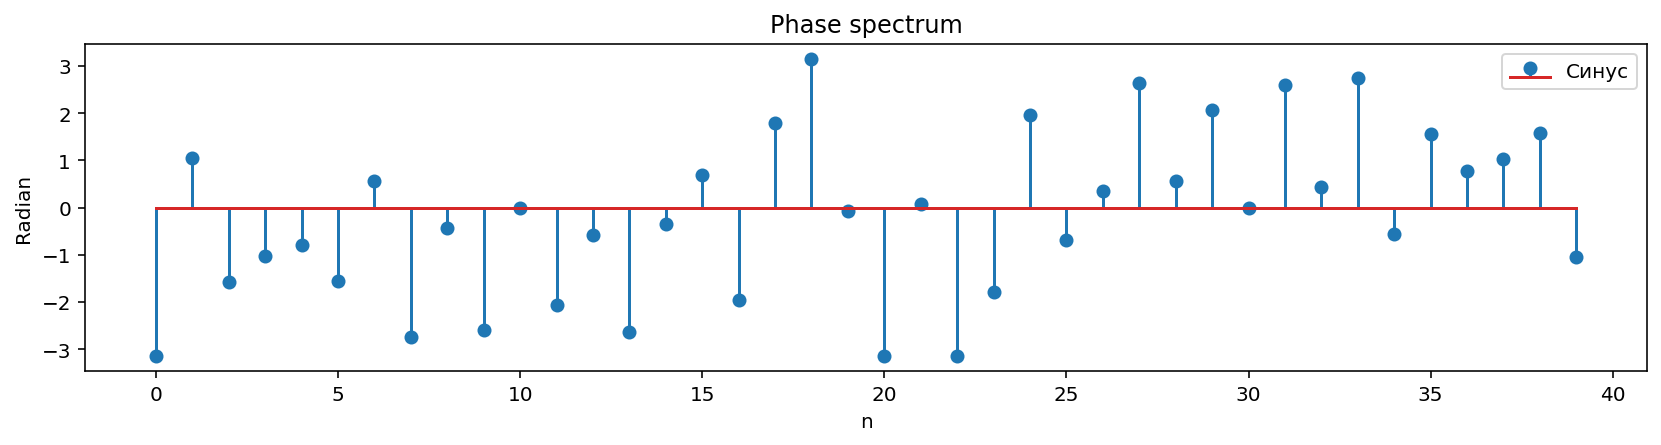

Шум:


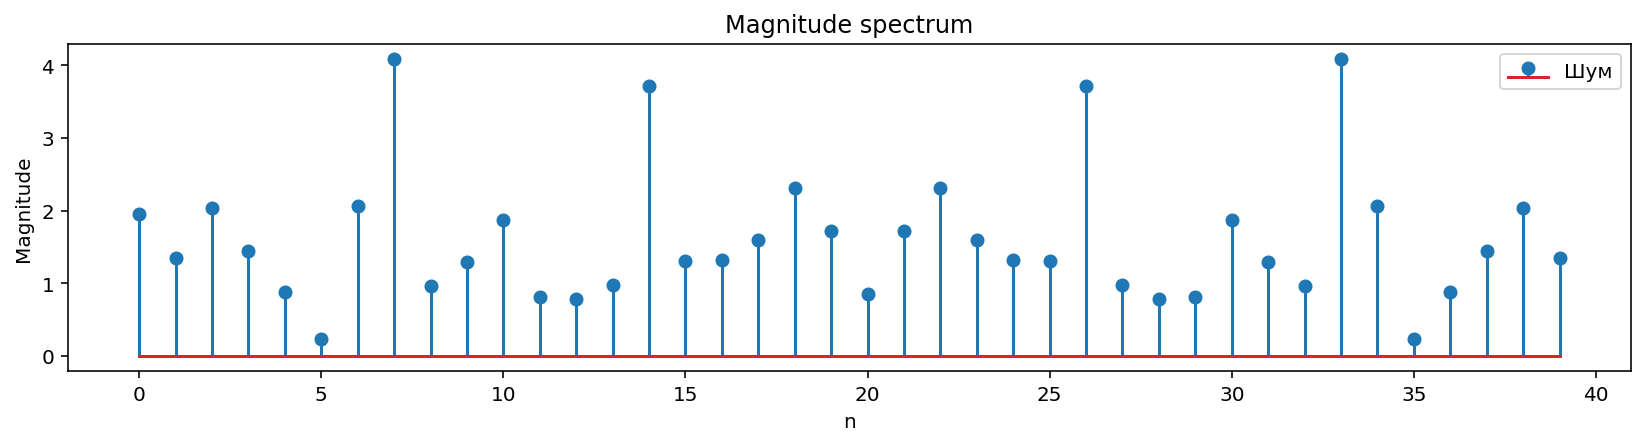

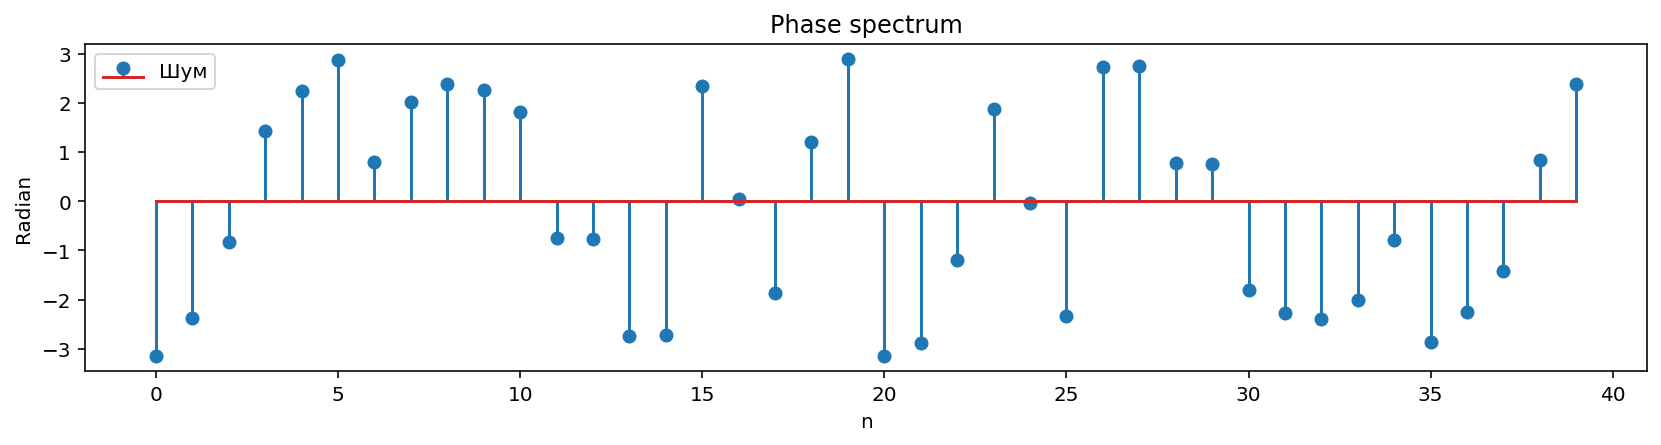

In [16]:
for name, sig in signals.items():
    print(f'{name}:')
    draw_spec(spec=scipy.fft.fft(sig), name=name)

1. Амплитуда всех гармоник единичного импульса равна единице, т.к. единичный импульс $\delta(n)$ равен нулю всюду, кроме точки $n = 0$, а в этой точке равен 1. Поэтому, в соответствии с формулой для прямого ДПФ, каждая составляющая спектра $X(k)$ будет вычисляться как сумма единицы и $N - 1$ нулей. Всё, как и должно быть, чем короче сигнал (а единичный имульс – это самый короткий сигнал из возможных, который мы можем наблюдать), тем шире его спектр.

2. Амплитудный спектр определяет амплитуды гармоник, из которых состоит исходный сигнал, т.е. по нему можно судить, как распределена энергия сигнала в частотной области. Фазовый спектр определяет начальные фазы этих гармоник. Исходя из того, что отсчёты спектра $X(k)$ и $X(-k)$ – комплексно сопряженные, следует свойство четности для амплитудного спектра и нечетности для фазового.

3. Чтобы преобразовать номер отчёта $k$ в частоту $f_k$, необходимо номер отсчёта $k$ умножить на частоту дискретизации $f_s$ и разделить полученное произведение на число отсчётов $N$:
$$f_k = \frac{f_s}{N}k$$

4. Комплексный спектр полностью определяется значениями на промежутке от 0 до $f_s/2$ (первая половина отсчётов ДПФ), этой информации достаточно для восстановления сигнала при обратном преобразовании, во второй половине информация дублируется.

# Оконное преобразование Фурье
Преобразование Фурье делает переход из временной области в частотную, позволяя анализировать составляющие сигнал гармоники. Однако это не всегда удобно. В реальных сигналах зачастую составляющие их гармоники изменяются со временем. Например, каждая буква в слове имеет свой набор основных гармоник, и простое преобразование Фурье не сильно поможет нам определить, что было сказано. Для того, чтобы анализировать такие сигналы, обычно используется [Оконное преобразование Фурье](https://ru.wikipedia.org/wiki/Оконное_преобразование_Фурье). Такое преобразование позволяет анализировать гармоники сигнала в коротких промежутках времени и сохранить временную ось при построении спектрограммы.
# Задание 3 (2 балла)
Реализовать оконное преобразование Фурье, пользуясь только библиотеками numpy и scipy. Сравнить с librosa.stft


In [17]:
def STFT(x, n_fft=2048, hop_length=512, window='hann'):
    #  Short-time Fourier transform
    # x - signal
    # n_fft - fft window size 
    # hop_length - step size between ffts
    # window - window type. See scipy.signal.get_window
    # return spectrogram
    
    fft_window = scipy.signal.get_window(window, n_fft, fftbins=True)
    fft_window = fft_window.reshape((-1, 1))
    # padding
    x = np.pad(x, int(n_fft // 2), mode='reflect')
    # number of frames
    n_frames = 1 + int((len(x) - n_fft) / hop_length)
    # vertical stride: one sample, horizontal stride: hop_length samples
    y_frames = np.lib.stride_tricks.as_strided(x, shape=(n_fft, n_frames), 
                                               strides=(x.itemsize, hop_length * x.itemsize))
    # spectrogram matrix
    stft_mat = np.empty((int(1 + n_fft // 2), y_frames.shape[1]), dtype=np.complex)
    str_c, col_c = stft_mat.shape[0], stft_mat.shape[1]

    for bl_beg in range(0, col_c, str_c):
        bl_end = min(bl_beg + str_c, col_c)
        stft_mat[:, bl_beg:bl_end] = scipy.fft.fft(y_frames[:, bl_beg:bl_end] * fft_window, 
                                                   axis=0)[:str_c]

    return stft_mat

In [18]:
def test_stft(x, n_fft=2048, hop_length=512, window='hann'):
    librosa_result = librosa.stft(x, n_fft=n_fft, hop_length=hop_length, window='hann', center=True)
    result = STFT(x, n_fft=n_fft, hop_length=hop_length, window='hann')
    if librosa_result.shape != result.shape:
        print(f"Your shape {result.shape} != librosa stft shape {librosa_result.shape} ")
        return -1 
    if not np.allclose(librosa_result, result):
        print(f"Wrong results. Diff {np.abs(librosa_result-result)}")
        return -2
    return 0
        
for name, sig in signals.items():
    print(f"Checking '{name}'")
    for n_fft in (8, 4):
        for hop_length in (n_fft//4, n_fft//2):
            assert test_stft(sig, n_fft=n_fft, hop_length=hop_length)==0, \
                f"Test failed. Params n_fft {n_fft}. Hop_length {hop_length}"
    print("ok")
print("All ok!")

Checking 'Единичный импульс'
ok
Checking 'Единичный скачок'
ok
Checking 'Синус'
ok
Checking 'Шум'
ok
All ok!


In [19]:
# Определим функцию для отрисовки
def draw_stft(X, sr, figsize=(14, 5)):
    plt.figure(figsize=figsize)
    # X - комплексная спектрограмма 
    # Для получения энергии достаточно взять модуль
    Xdb = librosa.amplitude_to_db(abs(X))
    librosa.display.specshow(Xdb, sr=sr, x_axis='time', y_axis='hz')
    plt.show()

# Анализ сигналов
Теперь можно приступить к анализу звуковых сигналов.
Во время анализа сигналов нам понадобятся все определенные выше инструменты. 


----------------------------------
## Анализ паровозного гудка
Начнем с простого сигнала, состоящего из нескольких основных гармоник и шума.

Len is 82175. Sample rate is 22050


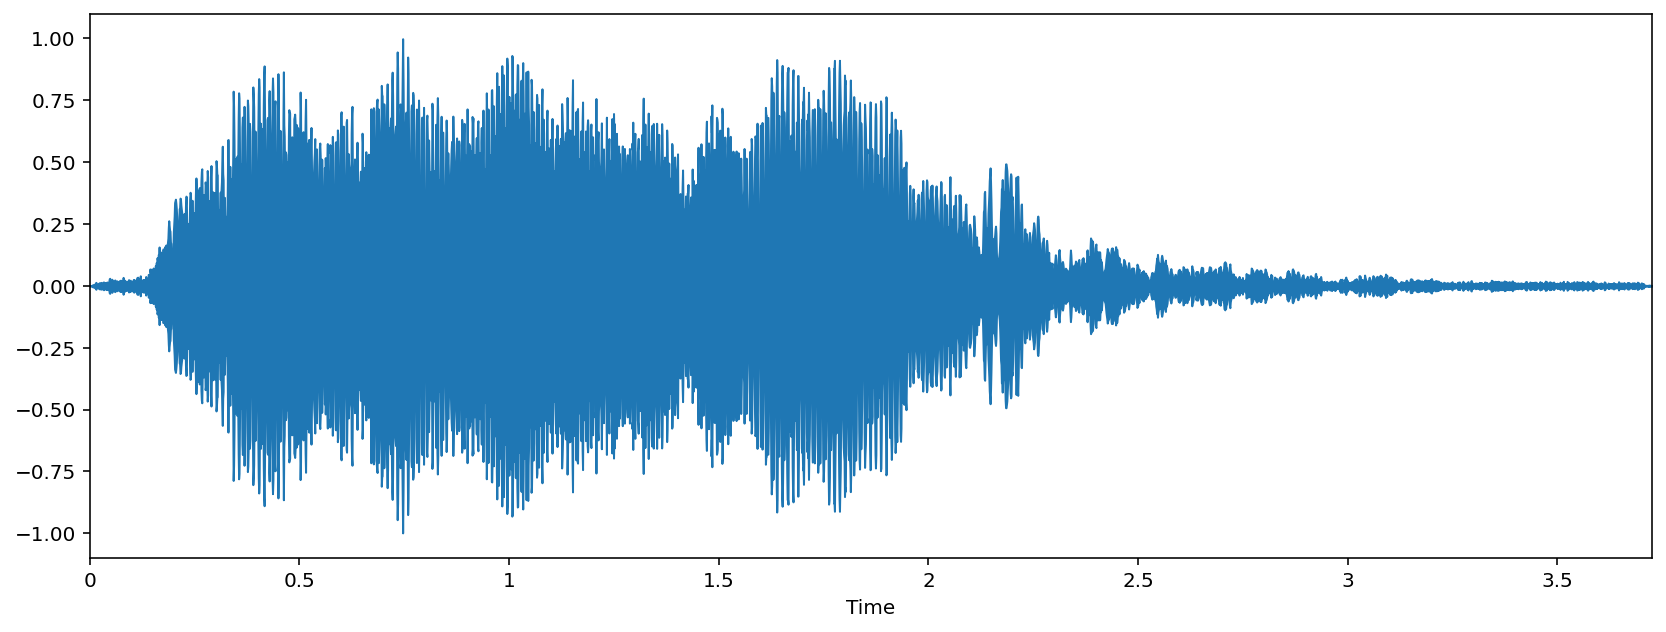

In [20]:
# Загрузим аудио файл с паровозным гудком
train_whistle, tw_sr = librosa.core.load("resources/train_whistle.wav")
print(f"Len is {len(train_whistle)}. Sample rate is {tw_sr}")
player = ipd.Audio(train_whistle, rate=tw_sr)
ipd.display(player)
draw_waveform(train_whistle, sr=tw_sr)

Гудок паровоза в частотной области


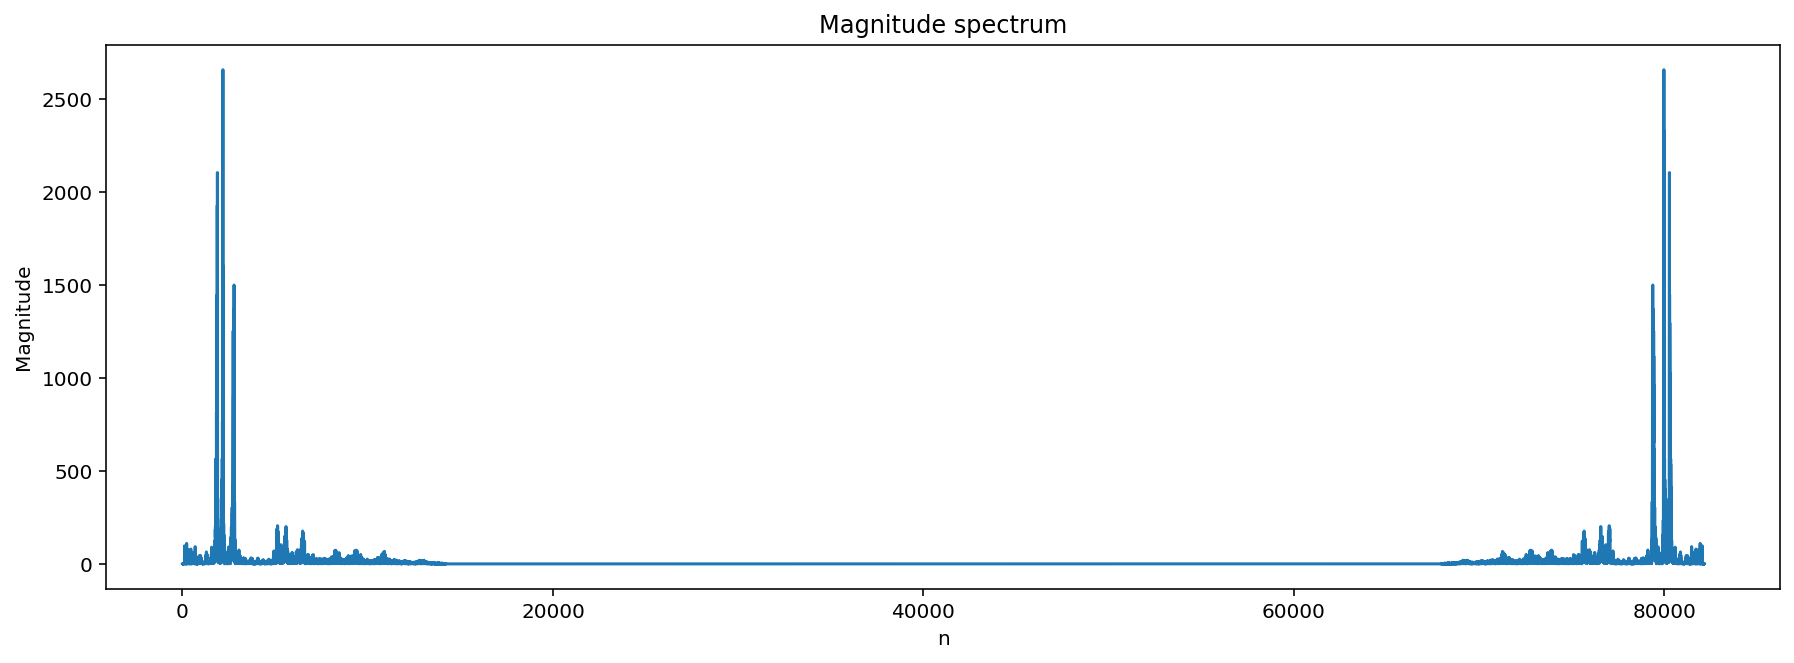

In [21]:
train_whistle_spec = scipy.fft.fft(train_whistle)
print("Гудок паровоза в частотной области")
draw_spec(train_whistle_spec, draw_p=False, figsize=(15, 5))

# Задание 4 (2 балла)
Определите 3 основные гармоники паровозного гудка.

Ответ округлите до двух знаков после запятой.

Рассчитаем ось частот для спектра сигнала train_whistle и отобразим интересующий нас участок его амплитудного спектра.

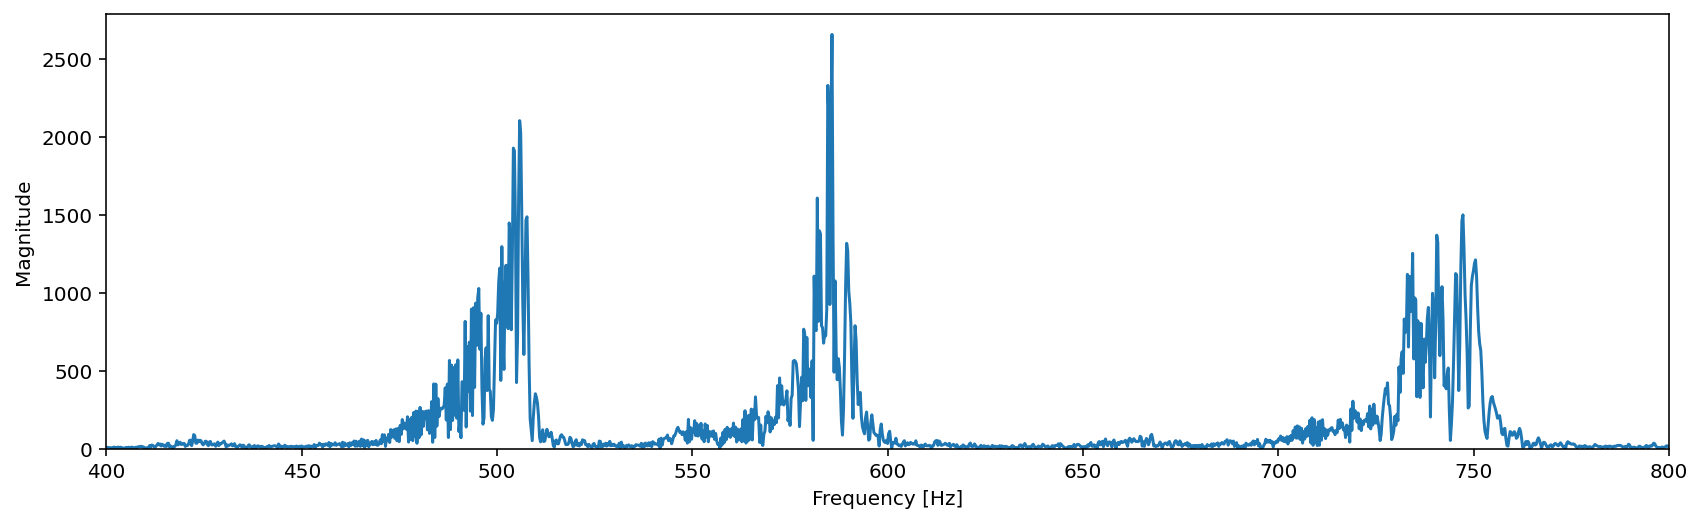

In [22]:
train_whistle_freqs = scipy.fft.fftfreq(len(train_whistle)) * tw_sr

_, ax = plt.subplots(figsize=(14, 4))
ax.plot(scipy.fft.fftshift(train_whistle_freqs), 
        scipy.fft.fftshift(np.abs(train_whistle_spec)))
ax.set_xlabel('Frequency [Hz]')
ax.set_ylabel('Magnitude')
ax.set_xlim(400, 800) # -tw_sr / 2, tw_sr / 2
ax.set_ylim(0,)
plt.show()

Определим функцию для поиска гармоник с максимальными амплитудами в заданной области спектра.

In [23]:
def find_local_max_freq(spec, freqs, freq_range=(None, None)):
    freq_idxs = np.where((freqs > freq_range[0]) & (freqs < freq_range[1]))
    abs_spec = np.abs(spec)[freq_idxs]
    max_freq = freqs[freq_idxs[0][np.argmax(abs_spec)]]
    return max_freq

In [24]:
freq_ranges = [(450, 550), (550, 650), (700, 800)]
for i, f_rng in enumerate(freq_ranges):
    max_freq = find_local_max_freq(train_whistle_spec, train_whistle_freqs, f_rng)
    print(f'f{i + 1} = {max_freq:.2f} Hz')

f1 = 505.80 Hz
f2 = 585.76 Hz
f3 = 747.30 Hz


Три соответствующих максимума можно наблюдать и на спектрограмме:

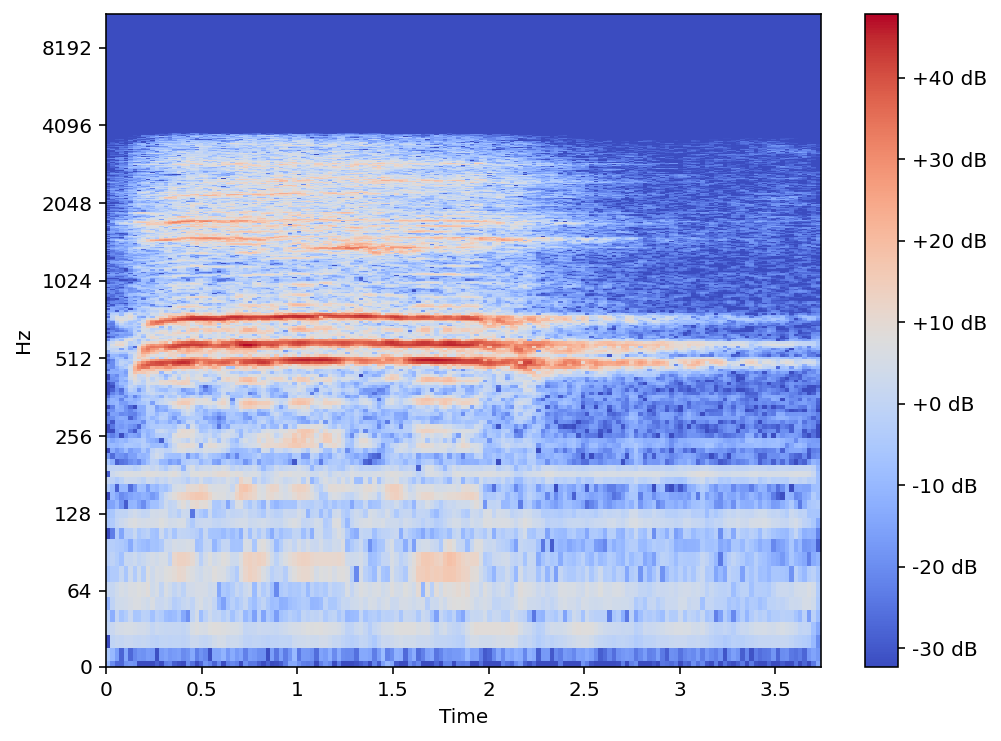

In [26]:
train_whistle_specgram = librosa.stft(train_whistle, n_fft=2048, hop_length=512, window='hann', center=True)
train_whistle_specgram_db = librosa.amplitude_to_db(abs(train_whistle_specgram))

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
img = librosa.display.specshow(train_whistle_specgram_db, sr=tw_sr, hop_length=512, x_axis='time', y_axis='log')
fig.colorbar(img, ax=ax, format="%+2.f dB")
plt.show()

In [27]:
task_answer = [505.8, 585.76, 747.3]

In [28]:
assert type(task_answer) == list or type(task_answer) == np.ndarray, \
        f"Wrong answer type. Expected list or numpy array. Got {type(task_answer)}"
assert len(task_answer) == 3, \
        f"Wrong len {len(task_answer)}."
assert (round(sum(task_answer)) == 1677 and round(np.var(task_answer)) == 1407) or \
        (abs(sum(task_answer)  - 1836) <= 3 and abs(np.var(task_answer) - 10153) <= 181), \
        f"Wrong freqs"
print("Correct!") 

Correct!


Теперь попробуйте сгенерировать сигнал, состоящий только из этих гармоник. Воспроизведите сигнал.

In [29]:
# трёхсекундный сигнал паровозного гудка
time_samples = np.linspace(0, 3, 3 * tw_sr)
tw_gen_signal = np.zeros(time_samples.shape[0])
for freq in task_answer:
    tw_gen_signal += np.sin(2 * np.pi * freq * time_samples)

In [30]:
ipd.Audio(tw_gen_signal, rate=tw_sr)

# Анализ двухтонального многочастотного сигнала
Теперь расмотрим более сложный сигнал - [DTMF](https://en.wikipedia.org/wiki/Dual-tone_multi-frequency_signaling). Такие сигналы используются для автоматизации набора телефонного номера. 

# Задание 5 (2 балла)
В данном аудио закодирован трехзначный номер. Используя таблицу из [статьи](https://ru.wikipedia.org/wiki/DTMF) определите, что за номер закодирован.


Len is 243102. Sample rate is 22050


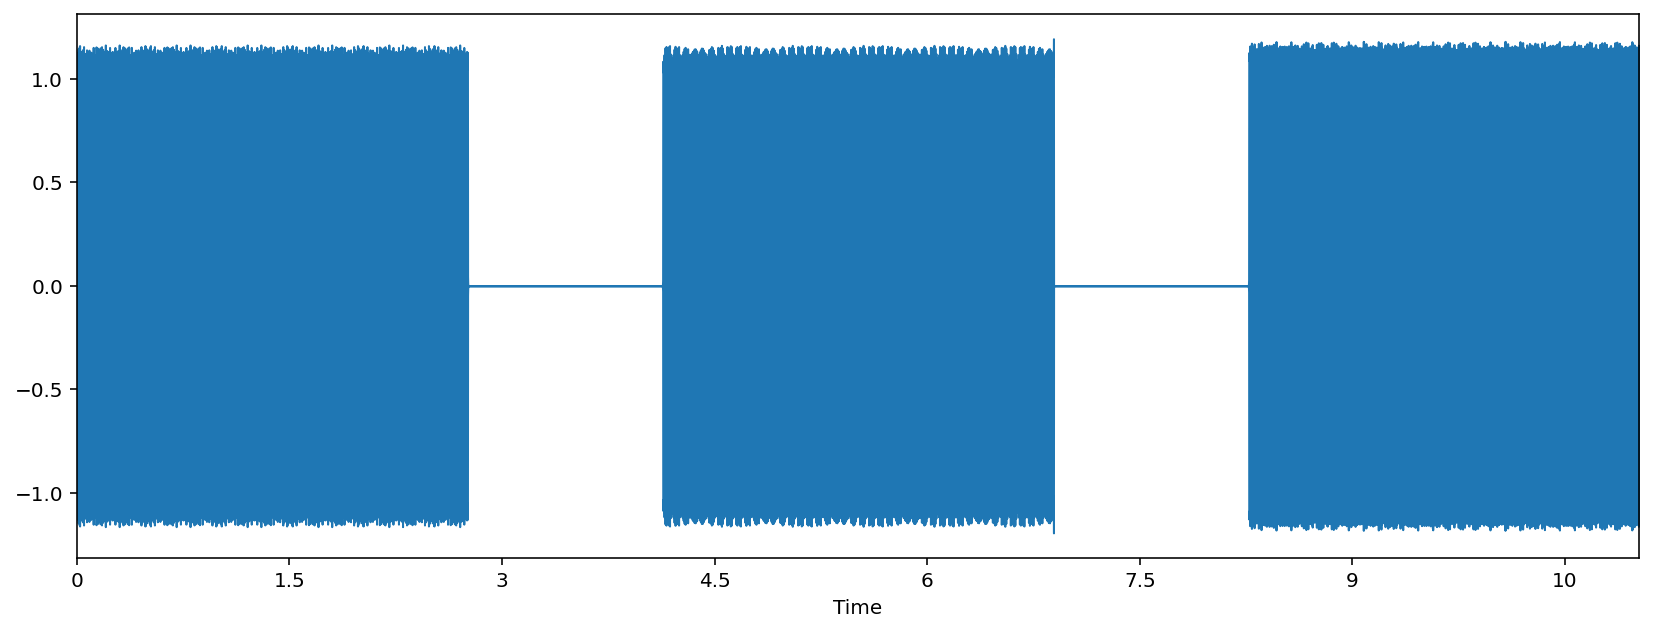

In [31]:
# dtmf.wav
dtmf, dtmf_sr = librosa.core.load("resources/dtmf.wav")
print(f"Len is {len(dtmf)}. Sample rate is {dtmf_sr}")
player = ipd.Audio(dtmf, rate=dtmf_sr)
ipd.display(player)
draw_waveform(dtmf, sr=dtmf_sr)

Построим спектрограмму DTMF-сигнала в логарифмическом масштабе частот (для наглядности).

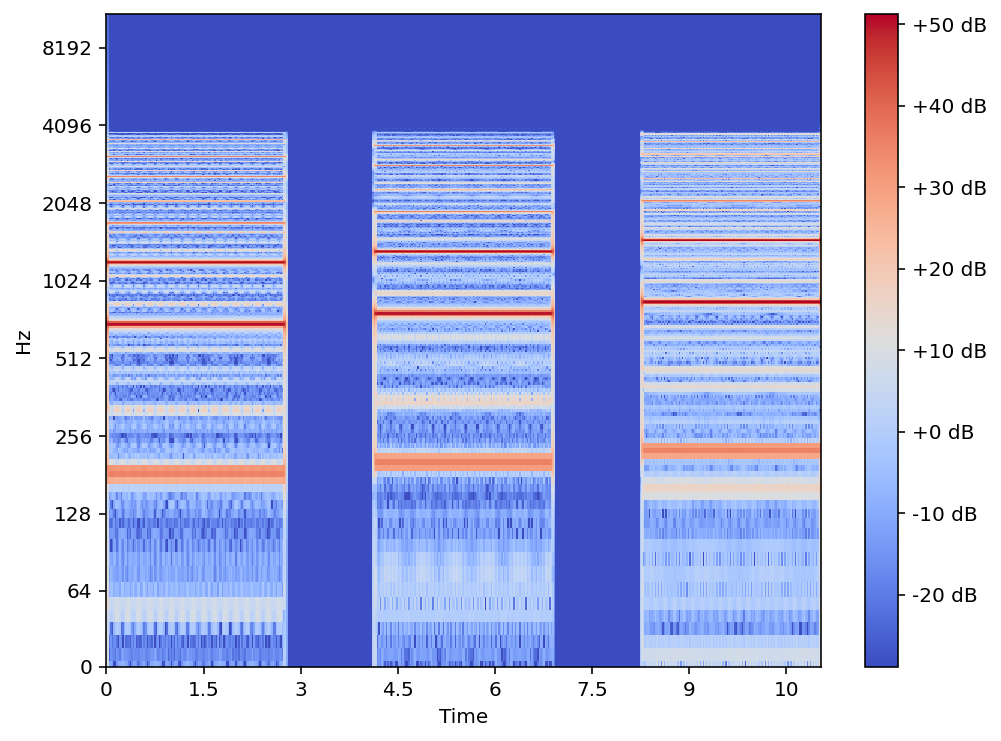

In [32]:
# dtmf_specgram = STFT(dtmf, n_fft=2048, hop_length=512, window='hann')
dtmf_specgram = librosa.stft(dtmf, n_fft=2048, hop_length=512, window='hann', center=True)
dtmf_specgram_db = librosa.amplitude_to_db(abs(dtmf_specgram))

# draw_stft(dtmf_specgram, dtmf_sr)
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
img = librosa.display.specshow(dtmf_specgram_db, sr=dtmf_sr, hop_length=512, x_axis='time', y_axis='log')
fig.colorbar(img, ax=ax, format="%+2.f dB")
plt.show()

В каждом из трёх последовательных сигналов на спектрограмме можно наблюдать по два красных пика гармоник, кодирующих соответственно цифры **1** (697 Гц, 1209 Гц), **5** (770 Гц, 1336 Гц) и **9** (852 Гц, 1477 Гц). Чтобы убедиться в этом, посмотрим на соответствующие временные сечения полученной спектрограммы для начала (первая цифра, t = 0 с), середины (вторая цифра, t = 5.5 с) и конца (третья цифра, t = 11 с) DTMF-сигнала. Для наглядности также отобразим на графике положение восьми кодирующих частот.

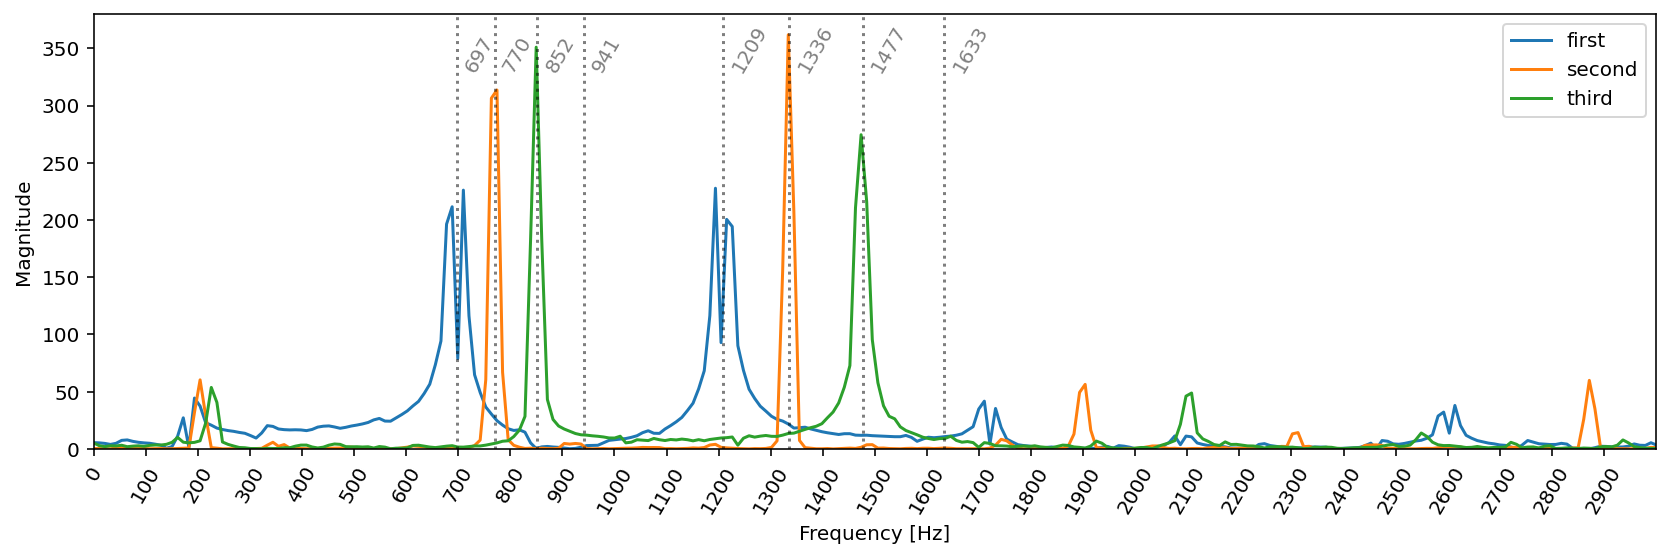

In [33]:
dtmf_specgram_freqs = scipy.fft.fftshift(scipy.fft.fftfreq(dtmf_specgram.shape[0])) * dtmf_sr / 2

# spectrums
plt.figure(figsize=(14, 4))
plt.plot(dtmf_specgram_freqs, 
         scipy.fft.fftshift(abs(dtmf_specgram[:, 0])),
         label = 'first')
plt.plot(dtmf_specgram_freqs, 
         scipy.fft.fftshift(abs(dtmf_specgram[:, dtmf_specgram.shape[1] // 2])),
         label = 'second')
plt.plot(dtmf_specgram_freqs, 
         scipy.fft.fftshift(abs(dtmf_specgram[:, dtmf_specgram.shape[1] - 1])),
         label = 'third')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')
plt.xlim(0, 3000)
plt.ylim(0,)
plt.legend()

# frequency axis stepsize
ax = plt.gca()
start_x, end_x = ax.get_xlim()
ax.xaxis.set_ticks(np.arange(start_x, end_x, 100)) # stepsize = 100 Hz
plt.xticks(rotation=60)

# DTMF keypad frequencies [Hz]
dtmf_keypad_freqs = [697, 770, 852, 941, 1209, 1336, 1477, 1633]
for f in dtmf_keypad_freqs:
    plt.axvline(x=f, ls='dotted', c='k', alpha=0.5)
    plt.text(f+10, 330, f, rotation=60, c='k', alpha=0.5)

plt.show()

In [34]:
# phone_number = [first: int, second: int, third: int]
phone_number = [1, 5, 9]

In [35]:
assert type(phone_number) == list or type(phone_number) == np.ndarray, \
        f"Wrong answer type. Expected list or numpy array. Got {type(phone_number)}"
assert len(phone_number) == 3, \
        f"Wrong len {len(phone_number)}."
assert round(np.mean(phone_number)) == 5 and round(np.var(phone_number)) == 11 , \
        f"Wrong number"
assert hashlib.md5(''.join(map(str, phone_number)).encode()).hexdigest() == "140f6969d5213fd0ece03148e62e461e", \
        f"Wrong hash. How did you pass mean/var test?"
print("Correct!")   

Correct!
